In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import datetime

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.metrics import (
    roc_auc_score, average_precision_score, precision_score, recall_score,
    f1_score, accuracy_score, confusion_matrix, roc_curve, precision_recall_curve,
    classification_report
)

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

pd.set_option("display.max_columns", 100)
print("Environment ready.")

Environment ready.


In [2]:
from google.colab import files

# Upload your Excel file
uploaded = files.upload()

# Get the uploaded file name
DATA_PATH = list(uploaded.keys())[0]

# Read the Excel file
df_raw = pd.read_excel(DATA_PATH)

# Convert Cutoff_Date to datetime
df_raw["Cutoff_Date"] = pd.to_datetime(df_raw["Cutoff_Date"])

# Display dataset shape
print("Shape:", df_raw.shape)

# Display the first 5 rows
display(df_raw.head())

Saving churn_early_warning_dataset.xlsx to churn_early_warning_dataset.xlsx
Shape: (2000, 17)


,Customer_Ref,Cutoff_Date,Gender,Age,Age_Group,Preferred_Service_Category,Visits_Last_90_Days_Before_Cutoff,Visits_Prior_90_Days_Before_That,Spend_Last_90_Days_Before_Cutoff_LKR,Spend_Prior_90_Days_Before_That_LKR,Spend_Trend_Ratio,Days_Since_Last_Visit_At_Cutoff,Avg_Visit_Interval_To_Date,Number_of_Unique_Services_To_Date,Number_of_Visits_To_Date,Customer_Tenure_Days_At_Cutoff,Churn_Within_90_Days
0,152,2024-05-20,Male,44,35-44,Injectables / Fillers,4,0,115510.29,0.00,115511.290,1,20.33,2,4,63,0
1,86,2025-06-20,Female,43,35-44,Laser / Hair Removal,2,1,29446.61,18536.33,1.589,31,53.80,3,6,301,0
2,187,2024-10-06,Female,44,35-44,Laser / Hair Removal,1,2,18087.03,48242.46,0.375,54,51.75,5,5,263,0
3,225,2025-05-03,Male,29,25-34,PRP / Regenerative Treatments,1,1,23026.05,25197.66,0.914,47,42.00,4,7,301,0
4,255,2024-09-13,Male,22,18-24,Facial / Medi Treatments,2,3,22840.27,75347.27,0.303,44,34.50,4,9,325,1


In [3]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                                Non-Null Count  Dtype         
---  ------                                --------------  -----         
 0   Customer_Ref                          2000 non-null   int64         
 1   Cutoff_Date                           2000 non-null   datetime64[ns]
 2   Gender                                2000 non-null   object        
 3   Age                                   2000 non-null   int64         
 4   Age_Group                             2000 non-null   object        
 5   Preferred_Service_Category            2000 non-null   object        
 6   Visits_Last_90_Days_Before_Cutoff     2000 non-null   int64         
 7   Visits_Prior_90_Days_Before_That      2000 non-null   int64         
 8   Spend_Last_90_Days_Before_Cutoff_LKR  2000 non-null   float64       
 9   Spend_Prior_90_Days_Before_That_LKR   2000 non-null   float64       
 10  

In [4]:
print("Missing values per column:")
print(df_raw.isnull().sum())

print("\nExact duplicate rows:", df_raw.duplicated().sum())
print("Duplicate Customer_Ref values:", df_raw["Customer_Ref"].duplicated().sum(),
      "(expected — the same customer can appear at multiple historical cutoff dates)")

df = df_raw.drop_duplicates().reset_index(drop=True)
print("\nShape after dropping exact duplicate rows:", df.shape)

Missing values per column:
Customer_Ref                            0
Cutoff_Date                             0
Gender                                  0
Age                                     0
Age_Group                               0
Preferred_Service_Category              0
Visits_Last_90_Days_Before_Cutoff       0
Visits_Prior_90_Days_Before_That        0
Spend_Last_90_Days_Before_Cutoff_LKR    0
Spend_Prior_90_Days_Before_That_LKR     0
Spend_Trend_Ratio                       0
Days_Since_Last_Visit_At_Cutoff         0
Avg_Visit_Interval_To_Date              0
Number_of_Unique_Services_To_Date       0
Number_of_Visits_To_Date                0
Customer_Tenure_Days_At_Cutoff          0
Churn_Within_90_Days                    0
dtype: int64

Exact duplicate rows: 2
Duplicate Customer_Ref values: 1746 (expected — the same customer can appear at multiple historical cutoff dates)

Shape after dropping exact duplicate rows: (1998, 17)


In [5]:
df.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Customer_Ref,1998.0,NaN,NaN,NaN,126.971471,1.0,60.0,128.0,188.0,258.0,74.234135
Cutoff_Date,1998,NaN,NaN,NaN,2025-01-27 13:24:19.459459584,2023-11-11 00:00:00,2024-08-29 06:00:00,2025-01-11 00:00:00,2025-06-26 18:00:00,2026-04-26 00:00:00,NaN
Gender,1998,2,Female,1008,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,1998.0,NaN,NaN,NaN,44.287788,18.0,32.0,44.0,57.0,70.0,14.882271
Age_Group,1998,6,55-64,417,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Preferred_Service_Category,1998,9,Acne / Scar Treatments,296,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Visits_Last_90_Days_Before_Cutoff,1998.0,NaN,NaN,NaN,2.075075,1.0,1.0,2.0,3.0,6.0,0.904764
Visits_Prior_90_Days_Before_That,1998.0,NaN,NaN,NaN,1.806807,0.0,1.0,2.0,2.0,6.0,0.983954
Spend_Last_90_Days_Before_Cutoff_LKR,1998.0,NaN,NaN,NaN,50896.544289,3325.26,21564.3125,40583.29,68552.9675,260381.67,39479.94519
Spend_Prior_90_Days_Before_That_LKR,1998.0,NaN,NaN,NaN,46293.347427,0.0,18063.36,35459.785,66911.35,235553.15,39628.766442


In [6]:
active_mask = df["Days_Since_Last_Visit_At_Cutoff"] < 90
print(f"Rows satisfying the active-customer rule (<90 days recency at cutoff): "
      f"{active_mask.sum()} / {len(df)} ({active_mask.mean():.1%})")

# Safety filter: if this ever runs on a raw extract that DID include inactive customers,
# we explicitly drop them here so the rule is enforced in code, not just by assumption.
df = df[active_mask].reset_index(drop=True)
print("Final modeling population:", df.shape)

Rows satisfying the active-customer rule (<90 days recency at cutoff): 1998 / 1998 (100.0%)
Final modeling population: (1998, 17)


Churn_Within_90_Days
Stayed active             0.786286
Churned within 90 days    0.213714
Name: proportion, dtype: float64


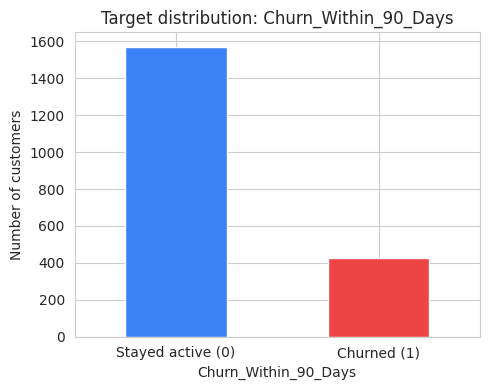

In [7]:
target_counts = df["Churn_Within_90_Days"].value_counts(normalize=True).rename({0: "Stayed active", 1: "Churned within 90 days"})
print(target_counts)

fig, ax = plt.subplots(figsize=(5, 4))
df["Churn_Within_90_Days"].value_counts().sort_index().plot(
    kind="bar", color=["#3B82F6", "#EF4444"], ax=ax
)
ax.set_xticklabels(["Stayed active (0)", "Churned (1)"], rotation=0)
ax.set_ylabel("Number of customers")
ax.set_title("Target distribution: Churn_Within_90_Days")
plt.tight_layout()
plt.show()

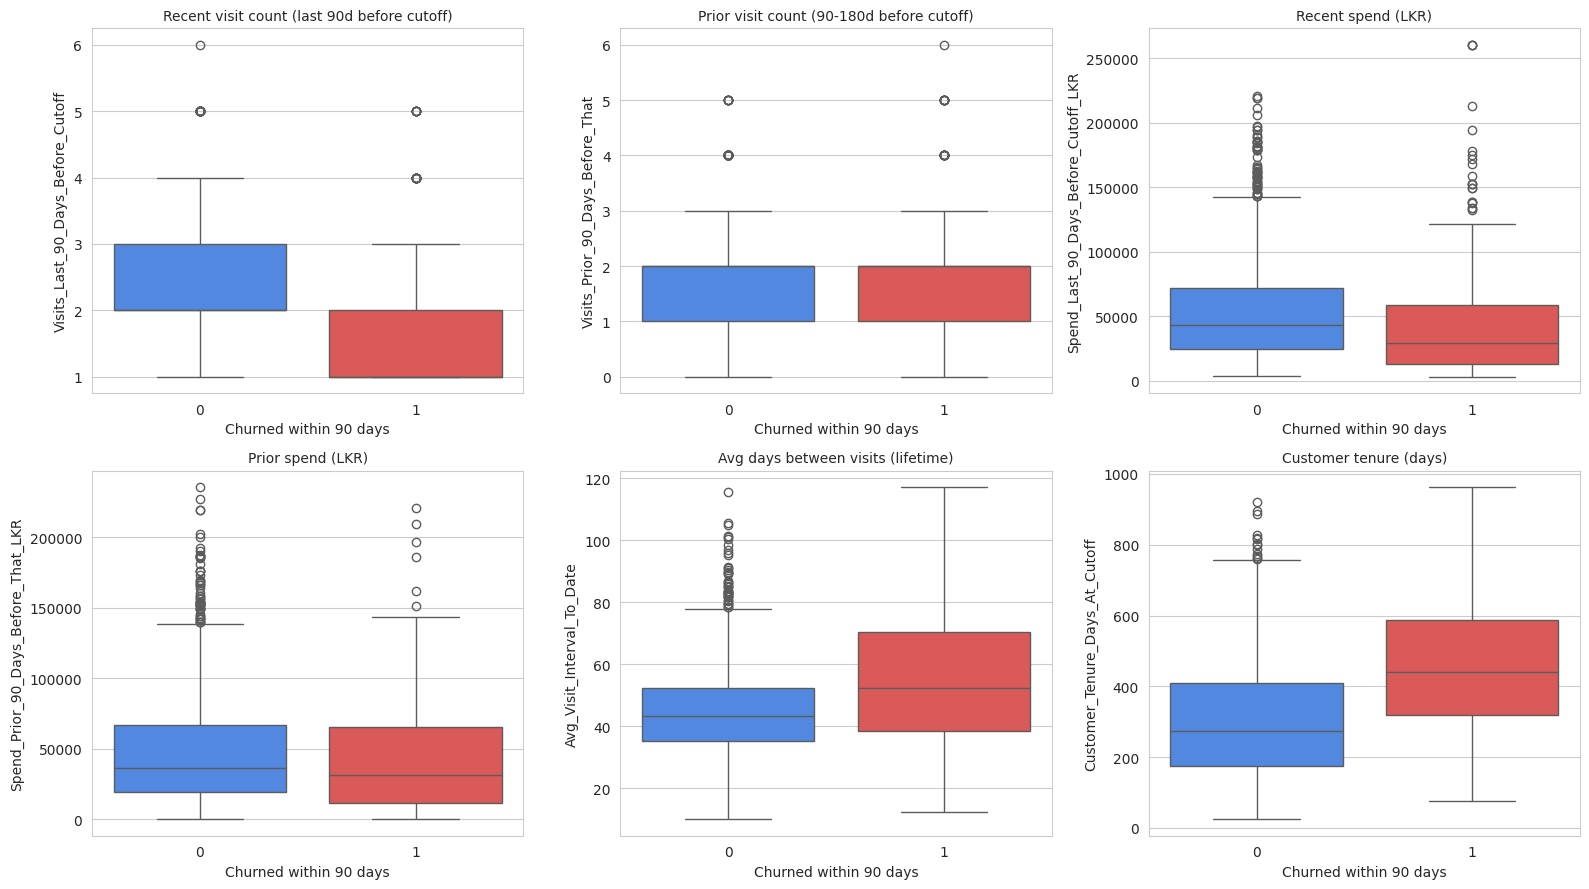

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

pairs = [
    ("Visits_Last_90_Days_Before_Cutoff", "Recent visit count (last 90d before cutoff)"),
    ("Visits_Prior_90_Days_Before_That", "Prior visit count (90-180d before cutoff)"),
    ("Spend_Last_90_Days_Before_Cutoff_LKR", "Recent spend (LKR)"),
    ("Spend_Prior_90_Days_Before_That_LKR", "Prior spend (LKR)"),
    ("Avg_Visit_Interval_To_Date", "Avg days between visits (lifetime)"),
    ("Customer_Tenure_Days_At_Cutoff", "Customer tenure (days)"),
]

for ax, (col, title) in zip(axes.flat, pairs):
    sns.boxplot(x="Churn_Within_90_Days", y=col, data=df, ax=ax, palette=["#3B82F6", "#EF4444"])
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Churned within 90 days")

plt.tight_layout()
plt.show()

In [9]:
from sklearn.model_selection import cross_val_score

X_recency_only = df[["Days_Since_Last_Visit_At_Cutoff"]]
y_check = df["Churn_Within_90_Days"]

auc_recency_only = cross_val_score(
    LogisticRegression(), X_recency_only, y_check, cv=5, scoring="roc_auc"
)
print(f"ROC-AUC using ONLY Days_Since_Last_Visit_At_Cutoff: {auc_recency_only.mean():.3f} (+/- {auc_recency_only.std():.3f})")

print(df.groupby("Churn_Within_90_Days")["Days_Since_Last_Visit_At_Cutoff"].describe()[["mean", "50%", "std"]])

ROC-AUC using ONLY Days_Since_Last_Visit_At_Cutoff: 0.595 (+/- 0.047)
                           mean   50%        std
Churn_Within_90_Days                            
0                     25.451305  22.0  19.302107
1                     33.843091  28.0  24.022118


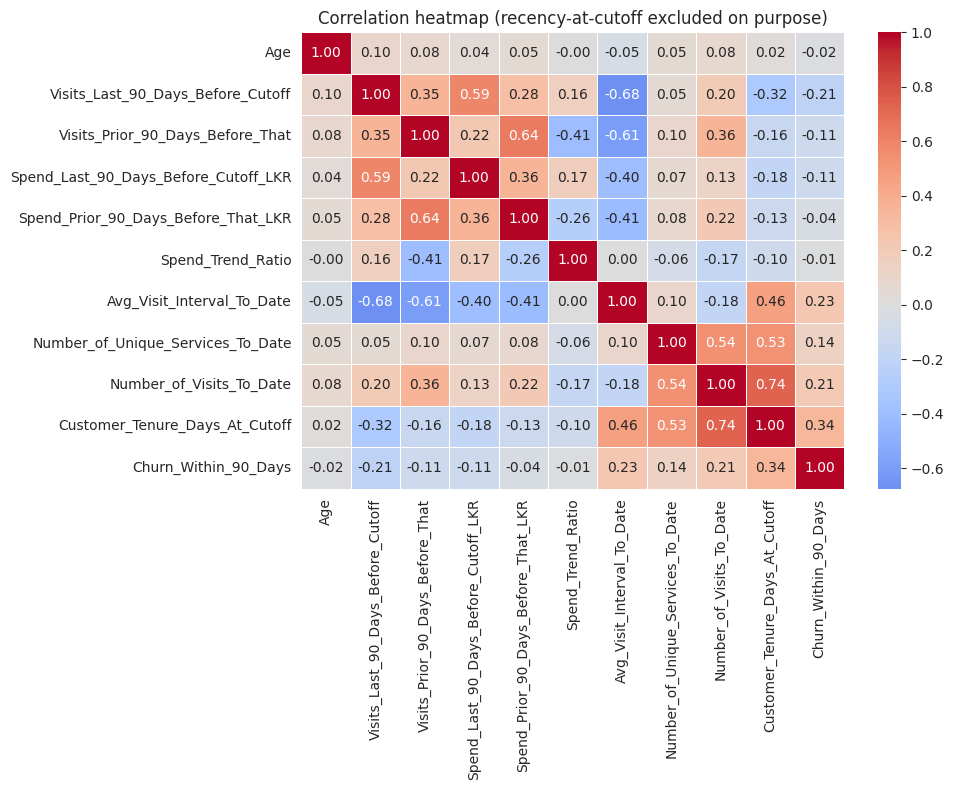

In [ ]:
numeric_cols_eda = df.select_dtypes(include=[np.number]).drop(
    columns=["Customer_Ref", "Days_Since_Last_Visit_At_Cutoff"]
)
plt.figure(figsize=(10, 8))
sns.heatmap(numeric_cols_eda.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Correlation heatmap (recency-at-cutoff excluded on purpose)")
plt.tight_layout()
plt.show()

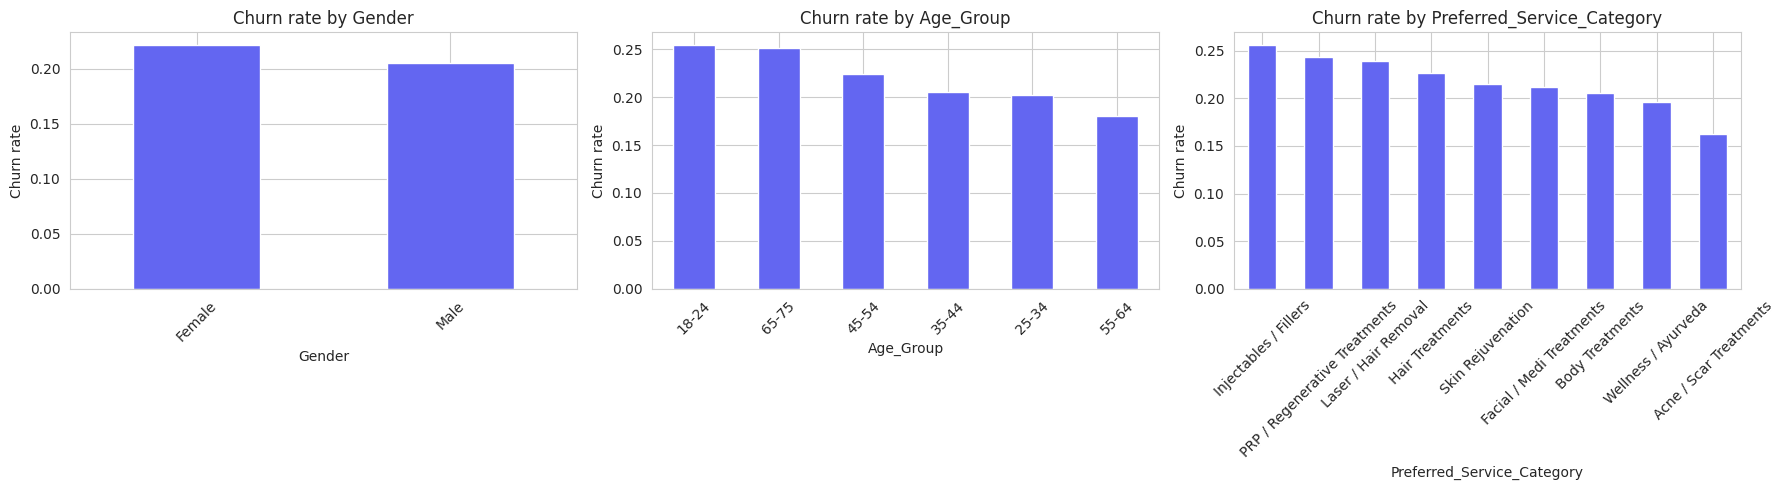

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, ["Gender", "Age_Group", "Preferred_Service_Category"]):
    rate = df.groupby(col)["Churn_Within_90_Days"].mean().sort_values(ascending=False)
    rate.plot(kind="bar", ax=ax, color="#6366F1")
    ax.set_ylabel("Churn rate")
    ax.set_title(f"Churn rate by {col}")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

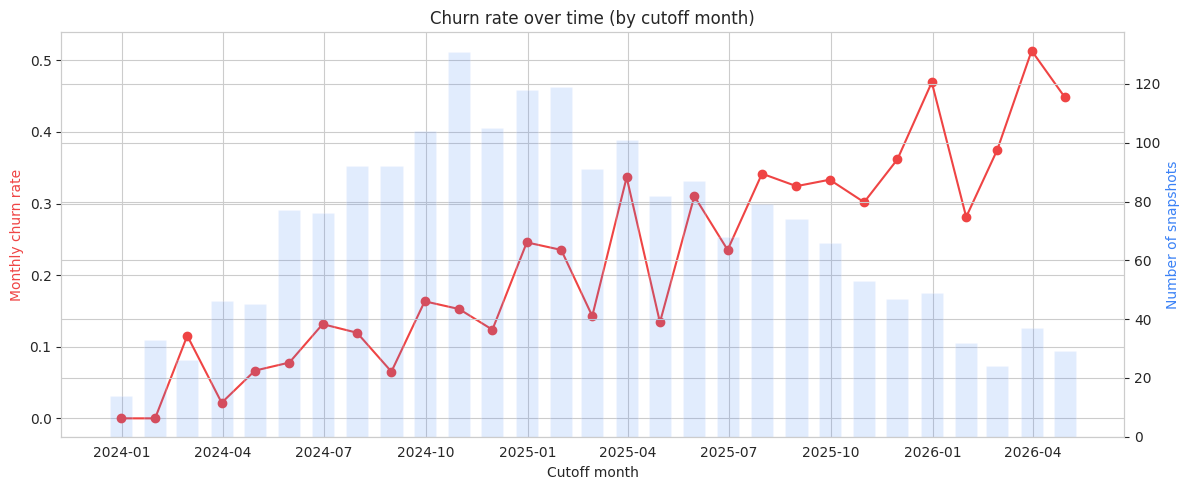

In [11]:
monthly_churn = df.set_index("Cutoff_Date").resample("ME")["Churn_Within_90_Days"].agg(["mean", "count"])
monthly_churn = monthly_churn[monthly_churn["count"] >= 10]  # ignore sparse early months

fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.plot(monthly_churn.index, monthly_churn["mean"], marker="o", color="#EF4444")
ax1.set_ylabel("Monthly churn rate", color="#EF4444")
ax1.set_xlabel("Cutoff month")
ax2 = ax1.twinx()
ax2.bar(monthly_churn.index, monthly_churn["count"], alpha=0.15, width=20, color="#3B82F6")
ax2.set_ylabel("Number of snapshots", color="#3B82F6")
plt.title("Churn rate over time (by cutoff month)")
plt.tight_layout()
plt.show()

In [12]:
EPS = 1  # additive smoothing to avoid division by zero, consistent across all ratio features

df["Visit_Trend_Ratio"] = (df["Visits_Last_90_Days_Before_Cutoff"] + EPS) / (df["Visits_Prior_90_Days_Before_That"] + EPS)
df["Visit_Trend_Delta"] = df["Visits_Last_90_Days_Before_Cutoff"] - df["Visits_Prior_90_Days_Before_That"]

cap_value = df["Spend_Trend_Ratio"].quantile(0.99)
df["Spend_Trend_Ratio_Capped"] = df["Spend_Trend_Ratio"].clip(upper=cap_value)

df["Spend_per_Visit_Last90"] = df["Spend_Last_90_Days_Before_Cutoff_LKR"] / df["Visits_Last_90_Days_Before_Cutoff"]
df["Spend_per_Visit_Prior90"] = df["Spend_Prior_90_Days_Before_That_LKR"] / (df["Visits_Prior_90_Days_Before_That"] + EPS)

df["Service_Diversity_Ratio"] = df["Number_of_Unique_Services_To_Date"] / df["Number_of_Visits_To_Date"]
df["Visits_Per_90D_Tenure"] = df["Number_of_Visits_To_Date"] / (df["Customer_Tenure_Days_At_Cutoff"] / 90)

engineered_cols = [
    "Visit_Trend_Ratio", "Visit_Trend_Delta", "Spend_Trend_Ratio_Capped",
    "Spend_per_Visit_Last90", "Spend_per_Visit_Prior90",
    "Service_Diversity_Ratio", "Visits_Per_90D_Tenure",
]
print(f"99th percentile cap applied to Spend_Trend_Ratio: {cap_value:.2f}")
print("\nAny inf/NaN introduced?",
      np.isinf(df[engineered_cols]).sum().sum(), "inf,",
      df[engineered_cols].isnull().sum().sum(), "NaN")

df[engineered_cols].describe().T

99th percentile cap applied to Spend_Trend_Ratio: 90025.65

Any inf/NaN introduced? 0 inf, 0 NaN


,count,mean,std,min,25%,50%,75%,max
Visit_Trend_Ratio,1998.0,1.247232,0.703317,0.285714,1.000000,1.000000,1.500000,6.000
Visit_Trend_Delta,1998.0,0.268268,1.076495,-5.000000,0.000000,0.000000,1.000000,5.000
Spend_Trend_Ratio_Capped,1998.0,3384.331927,14105.234790,0.033000,0.593250,1.133000,2.389500,90025.654
Spend_per_Visit_Last90,1998.0,24227.698995,15889.699685,3325.260000,12744.662500,19763.550000,30783.473750,97403.580
Spend_per_Visit_Prior90,1998.0,14920.886288,11355.017168,0.000000,7129.097500,12112.622917,20508.262500,62343.300
Service_Diversity_Ratio,1998.0,0.517849,0.216675,0.083333,0.333333,0.500000,0.666667,1.000
Visits_Per_90D_Tenure,1998.0,2.305833,0.869021,0.809769,1.722901,2.169864,2.666667,10.800


In [13]:
TARGET_COL = "Churn_Within_90_Days"

# Columns that must NEVER be used as model inputs:
#  - Customer_Ref      : identifier, no predictive meaning
#  - Cutoff_Date        : used only for the chronological split, not as a feature
#  - Days_Since_Last_Visit_At_Cutoff : recency-at-cutoff -- LEAKS the near-future answer (see Section 6.2)
#  - Spend_Trend_Ratio  : superseded by the capped, leakage-safe version engineered above
EXCLUDE_COLS = ["Customer_Ref", "Cutoff_Date", "Days_Since_Last_Visit_At_Cutoff", "Spend_Trend_Ratio"]

FEATURE_COLS = [c for c in df.columns if c not in EXCLUDE_COLS + [TARGET_COL]]
CATEGORICAL_COLS = ["Gender", "Age_Group", "Preferred_Service_Category"]
NUMERICAL_COLS = [c for c in FEATURE_COLS if c not in CATEGORICAL_COLS]

assert "Days_Since_Last_Visit_At_Cutoff" not in FEATURE_COLS, "Leakage guard failed!"

X = df[FEATURE_COLS].copy()
y = df[TARGET_COL].astype(int).copy()

print(f"{len(FEATURE_COLS)} features selected for modeling:\n")
for c in FEATURE_COLS:
    tag = "[categorical]" if c in CATEGORICAL_COLS else "[numeric]"
    print(f"  {tag:<14} {c}")

19 features selected for modeling:

  [categorical]  Gender
  [numeric]      Age
  [categorical]  Age_Group
  [categorical]  Preferred_Service_Category
  [numeric]      Visits_Last_90_Days_Before_Cutoff
  [numeric]      Visits_Prior_90_Days_Before_That
  [numeric]      Spend_Last_90_Days_Before_Cutoff_LKR
  [numeric]      Spend_Prior_90_Days_Before_That_LKR
  [numeric]      Avg_Visit_Interval_To_Date
  [numeric]      Number_of_Unique_Services_To_Date
  [numeric]      Number_of_Visits_To_Date
  [numeric]      Customer_Tenure_Days_At_Cutoff
  [numeric]      Visit_Trend_Ratio
  [numeric]      Visit_Trend_Delta
  [numeric]      Spend_Trend_Ratio_Capped
  [numeric]      Spend_per_Visit_Last90
  [numeric]      Spend_per_Visit_Prior90
  [numeric]      Service_Diversity_Ratio
  [numeric]      Visits_Per_90D_Tenure


In [14]:
split_date = df["Cutoff_Date"].quantile(0.80)
train_mask = df["Cutoff_Date"] <= split_date
test_mask = ~train_mask

X_train, y_train = X[train_mask].reset_index(drop=True), y[train_mask].reset_index(drop=True)
X_test, y_test = X[test_mask].reset_index(drop=True), y[test_mask].reset_index(drop=True)

print(f"Split date: {split_date.date()}")
print(f"Train: {X_train.shape[0]} rows | cutoffs {df.loc[train_mask,'Cutoff_Date'].min().date()} -> {df.loc[train_mask,'Cutoff_Date'].max().date()} | churn rate {y_train.mean():.1%}")
print(f"Test:  {X_test.shape[0]} rows | cutoffs {df.loc[test_mask,'Cutoff_Date'].min().date()} -> {df.loc[test_mask,'Cutoff_Date'].max().date()} | churn rate {y_test.mean():.1%}")

Split date: 2025-08-04
Train: 1601 rows | cutoffs 2023-11-11 -> 2025-08-04 | churn rate 17.6%
Test:  397 rows | cutoffs 2025-08-05 -> 2026-04-26 | churn rate 36.8%


In [15]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), NUMERICAL_COLS),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_COLS),
    ]
)

def make_pipeline(model):
    return ImbPipeline(steps=[
        ("preprocess", preprocessor),
        ("smote", SMOTE(random_state=RANDOM_SEED)),
        ("clf", model),
    ])

In [16]:
candidate_models = {
    "Logistic_Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_SEED),
    "Random_Forest": RandomForestClassifier(
        n_estimators=300, max_depth=10, random_state=RANDOM_SEED, class_weight="balanced"
    ),
    "XGBoost": XGBClassifier(
        n_estimators=300, max_depth=4, learning_rate=0.05,
        eval_metric="logloss", random_state=RANDOM_SEED
    ),
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
scoring = ["roc_auc", "average_precision", "recall", "precision", "f1"]

cv_summary = []
for name, model in candidate_models.items():
    pipe = make_pipeline(model)
    cv_result = cross_validate(pipe, X_train, y_train, cv=skf, scoring=scoring)
    row = {"Model": name}
    row.update({metric: cv_result[f"test_{metric}"].mean() for metric in scoring})
    cv_summary.append(row)

cv_summary_df = pd.DataFrame(cv_summary).sort_values("average_precision", ascending=False).reset_index(drop=True)
cv_summary_df

,Model,roc_auc,average_precision,recall,precision,f1
0,XGBoost,0.851675,0.563870,0.483960,0.605794,0.535545
1,Random_Forest,0.851437,0.546841,0.512343,0.577787,0.540920
2,Logistic_Regression,0.725216,0.412114,0.633647,0.312578,0.418572


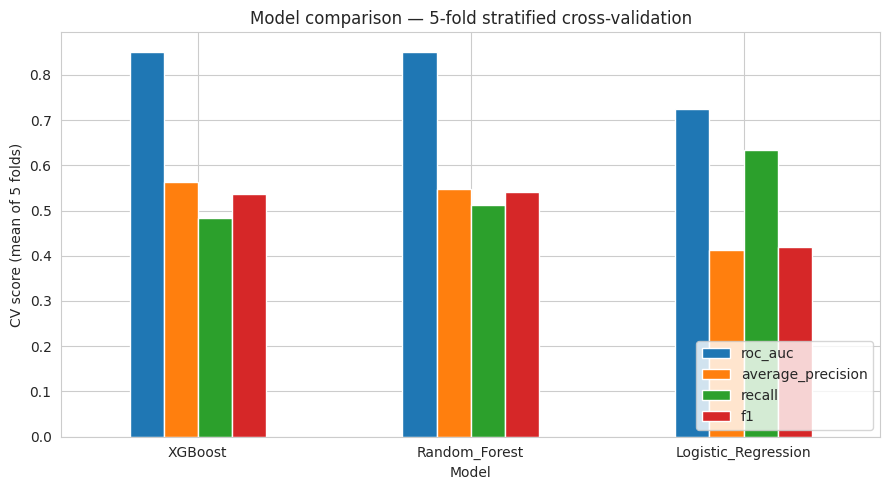

In [17]:
fig, ax = plt.subplots(figsize=(9, 5))
cv_summary_df.set_index("Model")[["roc_auc", "average_precision", "recall", "f1"]].plot(kind="bar", ax=ax)
ax.set_ylabel("CV score (mean of 5 folds)")
ax.set_title("Model comparison — 5-fold stratified cross-validation")
ax.legend(loc="lower right")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [18]:
BEST_MODEL_NAME = "XGBoost"
best_model = candidate_models[BEST_MODEL_NAME]
final_pipeline = make_pipeline(best_model)
final_pipeline.fit(X_train, y_train)
print(f"Selected model: {BEST_MODEL_NAME}")
print("Fitted on", X_train.shape[0], "training rows.")

Selected model: XGBoost
Fitted on 1601 training rows.


In [19]:
y_proba_test = final_pipeline.predict_proba(X_test)[:, 1]
y_pred_test = (y_proba_test >= 0.5).astype(int)

print(f"ROC-AUC:            {roc_auc_score(y_test, y_proba_test):.3f}")
print(f"Average Precision:  {average_precision_score(y_test, y_proba_test):.3f}")
print()
print(classification_report(y_test, y_pred_test, target_names=["Stayed active", "Churned"]))

ROC-AUC:            0.778
Average Precision:  0.711

               precision    recall  f1-score   support

Stayed active       0.78      0.76      0.77       251
      Churned       0.61      0.64      0.62       146

     accuracy                           0.72       397
    macro avg       0.70      0.70      0.70       397
 weighted avg       0.72      0.72      0.72       397



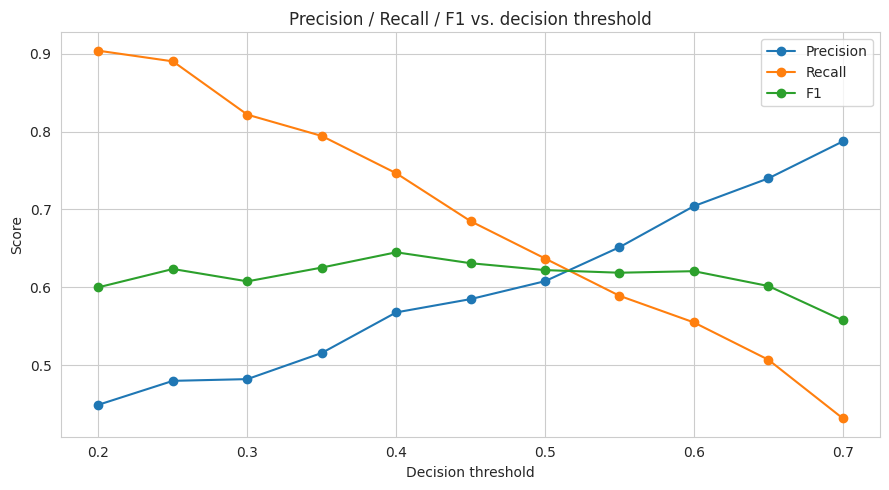

,threshold,precision,recall,f1,flagged_pct
0,0.20,0.448980,0.904110,0.600000,0.740554
1,0.25,0.479705,0.890411,0.623501,0.682620
2,0.30,0.481928,0.821918,0.607595,0.627204
3,0.35,0.515556,0.794521,0.625337,0.566751
4,0.40,0.567708,0.746575,0.644970,0.483627
5,0.45,0.584795,0.684932,0.630915,0.430730
6,0.50,0.607843,0.636986,0.622074,0.385390
7,0.55,0.651515,0.589041,0.618705,0.332494
8,0.60,0.704348,0.554795,0.620690,0.289673
9,0.65,0.740000,0.506849,0.601626,0.251889


In [20]:
thresholds = np.arange(0.2, 0.75, 0.05)
sweep = []
for t in thresholds:
    p = (y_proba_test >= t).astype(int)
    sweep.append({
        "threshold": round(t, 2),
        "precision": precision_score(y_test, p, zero_division=0),
        "recall": recall_score(y_test, p, zero_division=0),
        "f1": f1_score(y_test, p, zero_division=0),
        "flagged_pct": p.mean(),
    })
sweep_df = pd.DataFrame(sweep)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(sweep_df["threshold"], sweep_df["precision"], marker="o", label="Precision")
ax.plot(sweep_df["threshold"], sweep_df["recall"], marker="o", label="Recall")
ax.plot(sweep_df["threshold"], sweep_df["f1"], marker="o", label="F1")
ax.set_xlabel("Decision threshold")
ax.set_ylabel("Score")
ax.set_title("Precision / Recall / F1 vs. decision threshold")
ax.legend()
plt.tight_layout()
plt.show()

sweep_df

In [21]:
# Business-facing risk tiers, defined on predicted probability rather than a single cutoff.
RISK_THRESHOLDS = {"high": 0.55, "medium": 0.35}

def assign_risk_tier(proba, thresholds=RISK_THRESHOLDS):
    if proba >= thresholds["high"]:
        return "High"
    elif proba >= thresholds["medium"]:
        return "Medium"
    return "Low"

risk_tiers_test = pd.Series(y_proba_test).apply(assign_risk_tier)
tier_summary = pd.DataFrame({"risk_tier": risk_tiers_test, "actual_churn": y_test.values}).groupby("risk_tier").agg(
    customers=("actual_churn", "size"),
    actual_churn_rate=("actual_churn", "mean"),
).reindex(["High", "Medium", "Low"])

print("Chosen thresholds -> High >= 0.55, Medium >= 0.35, Low < 0.35\n")
tier_summary

Chosen thresholds -> High >= 0.55, Medium >= 0.35, Low < 0.35



,customers,actual_churn_rate
risk_tier,,
High,132,0.651515
Medium,93,0.322581
Low,172,0.174419


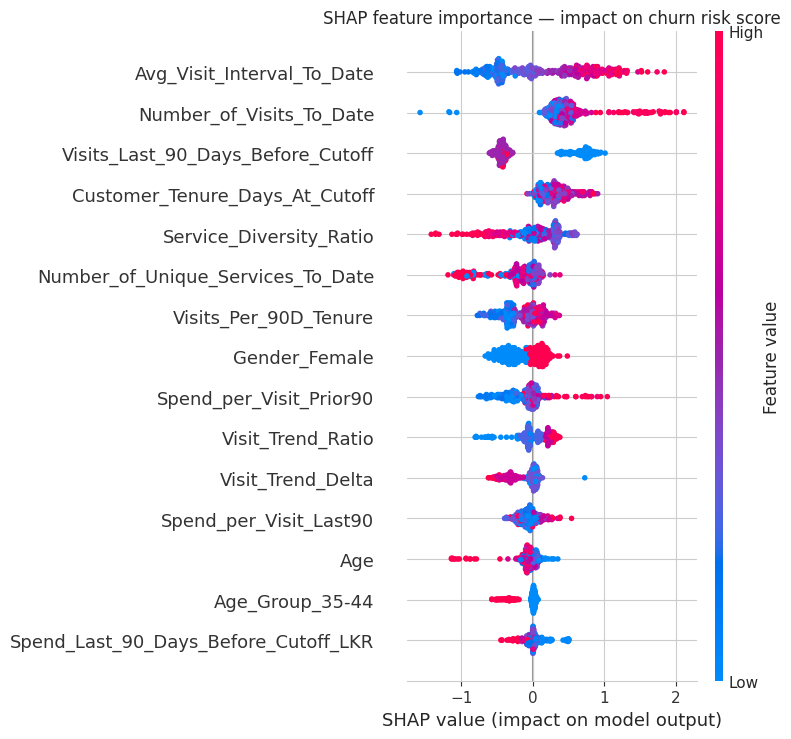

In [22]:
import shap

preprocess_step = final_pipeline.named_steps["preprocess"]
clf_step = final_pipeline.named_steps["clf"]

X_test_transformed = preprocess_step.transform(X_test)
cat_feature_names = preprocess_step.named_transformers_["cat"].get_feature_names_out(CATEGORICAL_COLS)
all_feature_names = NUMERICAL_COLS + list(cat_feature_names)

explainer = shap.TreeExplainer(clf_step)
shap_values = explainer.shap_values(X_test_transformed)

shap.summary_plot(
    shap_values,
    X_test_transformed,
    feature_names=all_feature_names,
    show=False,
    max_display=15,
)
plt.title("SHAP feature importance — impact on churn risk score")
plt.tight_layout()
plt.show()

In [24]:
MODEL_VERSION = "v2.0.0-early-warning-no-leakage"
TRAINING_DATE = datetime.datetime.now().isoformat()

model_package = {
    "pipeline": final_pipeline,                 # preprocessing + SMOTE + classifier, all in one object
    "feature_columns": FEATURE_COLS,
    "categorical_columns": CATEGORICAL_COLS,
    "numerical_columns": NUMERICAL_COLS,
    "excluded_columns": EXCLUDE_COLS,            # documents WHY these are excluded (see Section 8)
    "model_name": BEST_MODEL_NAME,
    "model_version": MODEL_VERSION,
    "training_date": TRAINING_DATE,
    "chronological_split_date": str(split_date.date()),
    "risk_thresholds": RISK_THRESHOLDS,
    "metrics": {
        "roc_auc_holdout": float(roc_auc_score(y_test, y_proba_test)),
        "average_precision_holdout": float(average_precision_score(y_test, y_proba_test)),
    },
    "active_customer_rule": "Only score customers with Days_Since_Last_Visit_At_Cutoff < 90",
}

SAVE_PATH = "churn_early_warning_model.joblib"
joblib.dump(model_package, SAVE_PATH)
print(f"Model package saved to: {SAVE_PATH}")
print(f"Version: {MODEL_VERSION}")
print(f"Holdout ROC-AUC: {model_package['metrics']['roc_auc_holdout']:.3f} | "
      f"Holdout AP: {model_package['metrics']['average_precision_holdout']:.3f}")

Model package saved to: churn_early_warning_model.joblib
Version: v2.0.0-early-warning-no-leakage
Holdout ROC-AUC: 0.778 | Holdout AP: 0.711


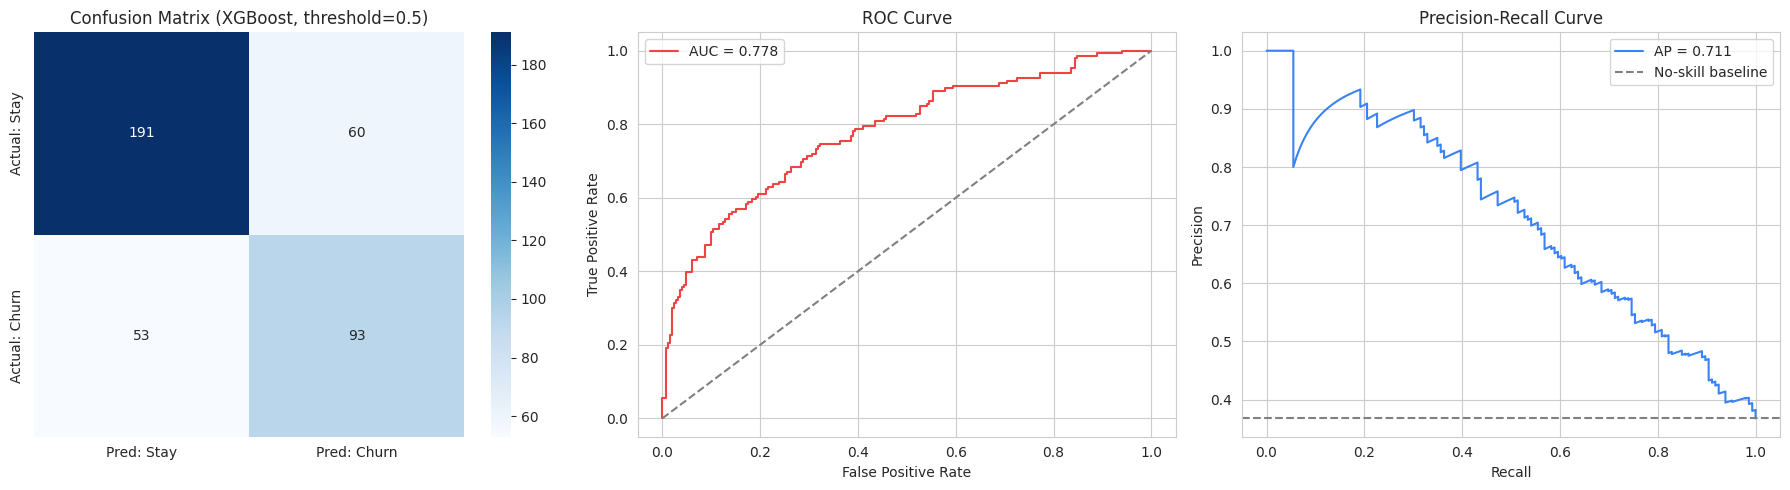

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred_test)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["Pred: Stay", "Pred: Churn"], yticklabels=["Actual: Stay", "Actual: Churn"])
axes[0].set_title(f"Confusion Matrix ({BEST_MODEL_NAME}, threshold=0.5)")

# ROC curve
fpr, tpr, _ = roc_curve(y_test, y_proba_test)
axes[1].plot(fpr, tpr, color="#EF4444", label=f"AUC = {roc_auc_score(y_test, y_proba_test):.3f}")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("ROC Curve")
axes[1].legend()

# Precision-Recall curve
prec, rec, _ = precision_recall_curve(y_test, y_proba_test)
axes[2].plot(rec, prec, color="#3B82F6", label=f"AP = {average_precision_score(y_test, y_proba_test):.3f}")
axes[2].axhline(y_test.mean(), linestyle="--", color="gray", label="No-skill baseline")
axes[2].set_xlabel("Recall")
axes[2].set_ylabel("Precision")
axes[2].set_title("Precision-Recall Curve")
axes[2].legend()

plt.tight_layout()
plt.show()

In [26]:
def predict_early_warning(customer_row, package, days_since_last_visit=None):
    # Score a single active customer.
    # customer_row: DataFrame with exactly package['feature_columns'] (no recency, no target).
    # days_since_last_visit: pass this in separately (NOT as a model feature) purely to enforce
    #                         the business rule that only currently-active customers get scored.
    if days_since_last_visit is not None and days_since_last_visit >= 90:
        return {
            "eligible": False,
            "reason": "Customer is not currently active (recency >= 90 days) — "
                      "already churned, not an early-warning candidate.",
        }

    X_sample = customer_row[package["feature_columns"]]
    proba = float(package["pipeline"].predict_proba(X_sample)[:, 1][0])
    tier = assign_risk_tier(proba, package["risk_thresholds"])

    return {
        "eligible": True,
        "churn_probability": round(proba, 4),
        "risk_tier": tier,
        "recommended_action": {
            "High": "Immediate personal outreach + strong retention offer",
            "Medium": "Automated re-engagement email / reminder",
            "Low": "No action needed",
        }[tier],
    }

In [27]:
def health_check(package_path):
    try:
        pkg = joblib.load(package_path)
        required_keys = ["pipeline", "feature_columns", "model_version", "excluded_columns"]
        for k in required_keys:
            assert k in pkg, f"Missing key: {k}"

        assert "Days_Since_Last_Visit_At_Cutoff" not in pkg["feature_columns"], "LEAKAGE GUARD FAILED"

        sample = X_test.iloc[[0]]
        proba = pkg["pipeline"].predict_proba(sample)[:, 1][0]
        assert 0 <= proba <= 1

        return {
            "status": "healthy",
            "model_version": pkg["model_version"],
            "n_features": len(pkg["feature_columns"]),
            "sample_prediction_ok": True,
        }
    except Exception as e:
        return {"status": "unhealthy", "error": str(e)}

health_check(SAVE_PATH)

{'status': 'healthy',
 'model_version': 'v2.0.0-early-warning-no-leakage',
 'n_features': 19,
 'sample_prediction_ok': True}

In [28]:
# Example customer A -- stable, engaged pattern (expected LOW risk)
customer_low_risk = pd.DataFrame([{
    "Gender": "Female", "Age": 33, "Age_Group": "25-34",
    "Preferred_Service_Category": "Skin Rejuvenation",
    "Visits_Last_90_Days_Before_Cutoff": 3, "Visits_Prior_90_Days_Before_That": 3,
    "Spend_Last_90_Days_Before_Cutoff_LKR": 68000, "Spend_Prior_90_Days_Before_That_LKR": 61000,
    "Avg_Visit_Interval_To_Date": 30.0, "Number_of_Unique_Services_To_Date": 4,
    "Number_of_Visits_To_Date": 12, "Customer_Tenure_Days_At_Cutoff": 360,
}])
customer_low_risk["Visit_Trend_Ratio"] = (customer_low_risk["Visits_Last_90_Days_Before_Cutoff"] + EPS) / (customer_low_risk["Visits_Prior_90_Days_Before_That"] + EPS)
customer_low_risk["Visit_Trend_Delta"] = customer_low_risk["Visits_Last_90_Days_Before_Cutoff"] - customer_low_risk["Visits_Prior_90_Days_Before_That"]
customer_low_risk["Spend_Trend_Ratio_Capped"] = ((customer_low_risk["Spend_Last_90_Days_Before_Cutoff_LKR"] + EPS) / (customer_low_risk["Spend_Prior_90_Days_Before_That_LKR"] + EPS)).clip(upper=cap_value)
customer_low_risk["Spend_per_Visit_Last90"] = customer_low_risk["Spend_Last_90_Days_Before_Cutoff_LKR"] / customer_low_risk["Visits_Last_90_Days_Before_Cutoff"]
customer_low_risk["Spend_per_Visit_Prior90"] = customer_low_risk["Spend_Prior_90_Days_Before_That_LKR"] / (customer_low_risk["Visits_Prior_90_Days_Before_That"] + EPS)
customer_low_risk["Service_Diversity_Ratio"] = customer_low_risk["Number_of_Unique_Services_To_Date"] / customer_low_risk["Number_of_Visits_To_Date"]
customer_low_risk["Visits_Per_90D_Tenure"] = customer_low_risk["Number_of_Visits_To_Date"] / (customer_low_risk["Customer_Tenure_Days_At_Cutoff"] / 90)

# Example customer B -- fading engagement pattern (expected HIGH risk)
customer_high_risk = pd.DataFrame([{
    "Gender": "Male", "Age": 47, "Age_Group": "45-54",
    "Preferred_Service_Category": "Laser / Hair Removal",
    "Visits_Last_90_Days_Before_Cutoff": 1, "Visits_Prior_90_Days_Before_That": 4,
    "Spend_Last_90_Days_Before_Cutoff_LKR": 9000, "Spend_Prior_90_Days_Before_That_LKR": 70000,
    "Avg_Visit_Interval_To_Date": 65.0, "Number_of_Unique_Services_To_Date": 2,
    "Number_of_Visits_To_Date": 8, "Customer_Tenure_Days_At_Cutoff": 300,
}])
customer_high_risk["Visit_Trend_Ratio"] = (customer_high_risk["Visits_Last_90_Days_Before_Cutoff"] + EPS) / (customer_high_risk["Visits_Prior_90_Days_Before_That"] + EPS)
customer_high_risk["Visit_Trend_Delta"] = customer_high_risk["Visits_Last_90_Days_Before_Cutoff"] - customer_high_risk["Visits_Prior_90_Days_Before_That"]
customer_high_risk["Spend_Trend_Ratio_Capped"] = ((customer_high_risk["Spend_Last_90_Days_Before_Cutoff_LKR"] + EPS) / (customer_high_risk["Spend_Prior_90_Days_Before_That_LKR"] + EPS)).clip(upper=cap_value)
customer_high_risk["Spend_per_Visit_Last90"] = customer_high_risk["Spend_Last_90_Days_Before_Cutoff_LKR"] / customer_high_risk["Visits_Last_90_Days_Before_Cutoff"]
customer_high_risk["Spend_per_Visit_Prior90"] = customer_high_risk["Spend_Prior_90_Days_Before_That_LKR"] / (customer_high_risk["Visits_Prior_90_Days_Before_That"] + EPS)
customer_high_risk["Service_Diversity_Ratio"] = customer_high_risk["Number_of_Unique_Services_To_Date"] / customer_high_risk["Number_of_Visits_To_Date"]
customer_high_risk["Visits_Per_90D_Tenure"] = customer_high_risk["Number_of_Visits_To_Date"] / (customer_high_risk["Customer_Tenure_Days_At_Cutoff"] / 90)

loaded_package = joblib.load(SAVE_PATH)

result_low = predict_early_warning(customer_low_risk, loaded_package, days_since_last_visit=15)
result_high = predict_early_warning(customer_high_risk, loaded_package, days_since_last_visit=40)
result_inactive = predict_early_warning(customer_high_risk, loaded_package, days_since_last_visit=120)

print("=== CUSTOMER A (stable engagement pattern) ===")
print(result_low)
print("\n=== CUSTOMER B (fading engagement pattern) ===")
print(result_high)
print("\n=== CUSTOMER C (already inactive -- recency=120 days) ===")
print(result_inactive)

=== CUSTOMER A (stable engagement pattern) ===
{'eligible': True, 'churn_probability': 0.2926, 'risk_tier': 'Low', 'recommended_action': 'No action needed'}

=== CUSTOMER B (fading engagement pattern) ===
{'eligible': True, 'churn_probability': 0.7942, 'risk_tier': 'High', 'recommended_action': 'Immediate personal outreach + strong retention offer'}

=== CUSTOMER C (already inactive -- recency=120 days) ===
{'eligible': False, 'reason': 'Customer is not currently active (recency >= 90 days) — already churned, not an early-warning candidate.'}


In [29]:
import pandas as pd

df = pd.read_excel("churn_early_warning_dataset.xlsx")
df["Cutoff_Date"] = pd.to_datetime(df["Cutoff_Date"])
print("Rows as loaded:", len(df))

df = df.drop_duplicates()
print("Rows after de-duplication:", len(df))

print("First snapshot:", df["Cutoff_Date"].min().date())
print("Last snapshot: ", df["Cutoff_Date"].max().date())
split = df["Cutoff_Date"].quantile(0.8)
print("80th percentile split date:", split.date())
print("Training rows (on/before split):", (df["Cutoff_Date"] <= split).sum())

Rows as loaded: 2000
Rows after de-duplication: 1998
First snapshot: 2023-11-11
Last snapshot:  2026-04-26
80th percentile split date: 2025-08-04
Training rows (on/before split): 1601


In [30]:
# ===== Paste into ONE new cell at the END of your Colab notebook (version 2) =====
# Needs: the notebook run top to bottom in this session (X_test, y_test exist),
# plus churn_early_warning_dataset.xlsx and churn_early_warning_model.joblib in /content.

import joblib
import numpy as np
import pandas as pd

CONTRACT = [
    "Gender", "Age", "Age_Group", "Preferred_Service_Category",
    "Visits_Last_90_Days_Before_Cutoff", "Visits_Prior_90_Days_Before_That",
    "Spend_Last_90_Days_Before_Cutoff_LKR", "Spend_Prior_90_Days_Before_That_LKR",
    "Avg_Visit_Interval_To_Date", "Number_of_Unique_Services_To_Date",
    "Number_of_Visits_To_Date", "Customer_Tenure_Days_At_Cutoff",
    "Days_Since_Last_Visit_At_Cutoff",
]

def to01(series):
    """Turn Yes/No, True/False, Churned/Stayed or 1/0 into 1/0."""
    s = pd.Series(series).astype(str).str.strip().str.lower()
    s = s.replace({"true": "1", "yes": "1", "churned": "1", "false": "0", "no": "0", "stayed": "0", "active": "0"})
    return pd.to_numeric(s, errors="coerce").fillna(-1).astype(int).values

def same_rows(cand):
    """True if cand has the same rows, in the same order, as X_test / y_test."""
    if cand is None or len(cand) != len(y_test) or target not in cand.columns:
        return False
    if not (to01(cand[target]) == to01(y_test)).all():
        return False
    for c in [c for c in X_test.columns if c in cand.columns]:   # feature values must match too
        a, b = cand[c].values, X_test[c].values
        if pd.api.types.is_numeric_dtype(X_test[c]):
            if not np.allclose(pd.to_numeric(a, errors="coerce"), b.astype(float), equal_nan=True):
                return False
        elif not (pd.Series(a).astype(str).values == pd.Series(b).astype(str).values).all():
            return False
    return True

pkg = joblib.load("/content/churn_early_warning_model.joblib")
print("Model version:", pkg.get("model_version"))
print("Risk thresholds:", pkg.get("risk_thresholds"))

raw = pd.read_excel("/content/churn_early_warning_dataset.xlsx")
raw["Cutoff_Date"] = pd.to_datetime(raw["Cutoff_Date"])
target = y_test.name
split = pd.Timestamp(pkg["chronological_split_date"])

# Try several ways of finding the raw holdout rows, keep the first that matches exactly
candidates = []
try:
    candidates.append(("raw rows by X_test index", raw.loc[X_test.index]))
except Exception:
    pass
for name, obj in list(globals().items()):          # dataframes the notebook already has in memory
    if isinstance(obj, pd.DataFrame) and not name.startswith("_") and target in obj.columns:
        try:
            candidates.append((f"notebook dataframe '{name}' by X_test index", obj.loc[X_test.index]))
        except Exception:
            pass
dedup = raw.drop_duplicates()
for label, base in [("de-duplicated, sorted by date", dedup), ("sorted by date", raw)]:
    s = base.sort_values("Cutoff_Date", kind="mergesort").reset_index(drop=True)
    candidates.append((label + ", after split", s[s["Cutoff_Date"] > split]))

# Last resort: pair each X_test row with the Excel row that has identical feature values
try:
    after = dedup[dedup["Cutoff_Date"] > split].copy()
    keys = [c for c in X_test.columns if c in after.columns]
    def key_of(frame, labels):
        parts = [frame[c].round(6).astype(str) if pd.api.types.is_numeric_dtype(frame[c]) else frame[c].astype(str) for c in keys]
        return pd.Series(list(zip(*parts, labels)), index=frame.index)
    pool = {}
    for idx, k in key_of(after, to01(after[target])).items():
        pool.setdefault(k, []).append(idx)
    picked = [pool[k].pop(0) for k in key_of(X_test, to01(y_test))]
    candidates.append(("matched by feature values", after.loc[picked]))
except Exception:
    pass

hold, used = None, None
for label, cand in candidates:
    if same_rows(cand):
        hold, used = cand.copy(), label
        break

if hold is None:
    print("\nCOULD NOT MATCH THE HOLDOUT ROWS. Please screenshot everything below:")
    print("target:", target, "| y_test first 5:", list(y_test.head()))
    print("Excel target first 5:", list(raw[target].head()) if target in raw.columns else "column not in Excel")
    print("X_test index first 5:", list(X_test.index[:5]))
    print("X_test columns:", list(X_test.columns))
    print("Excel columns:", list(raw.columns))
    print("Tried:", [c[0] for c in candidates])
else:
    missing = [c for c in CONTRACT if c not in hold.columns]
    assert not missing, f"Missing columns: {missing}"
    print("Matched using:", used)
    print("Holdout rows:", len(hold), "| target column:", target, "| churn rate:", round(to01(y_test).mean(), 3))

    hold["expected_probability"] = pkg["pipeline"].predict_proba(X_test[pkg["feature_columns"]])[:, 1]
    hold["actual_churned"] = to01(y_test)
    out = hold[["Customer_Ref", "Cutoff_Date"] + CONTRACT + ["actual_churned", "expected_probability"]]
    out.to_csv("holdout_for_live_test.csv", index=False)
    print("Saved holdout_for_live_test.csv")
    from google.colab import files
    files.download("holdout_for_live_test.csv")

Model version: v2.0.0-early-warning-no-leakage
Risk thresholds: {'high': 0.55, 'medium': 0.35}
Matched using: matched by feature values
Holdout rows: 397 | target column: Churn_Within_90_Days | churn rate: 0.368
Saved holdout_for_live_test.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [31]:
import pandas as pd

d = df.copy()
d["Cutoff_Date"] = pd.to_datetime(d["Cutoff_Date"])
split = pd.Timestamp("2025-08-04")
train_part = d[d["Cutoff_Date"] <= split]
hold_part = d[d["Cutoff_Date"] > split]

cap_train = train_part["Spend_Trend_Ratio"].quantile(0.99)

print("EXACT cap used by the model (copy this):", repr(float(cap_value)))
print("Cap if computed on training rows only:  ", round(float(cap_train), 4))
print("Rows used for each:", len(d), "vs", len(train_part))
print("Holdout rows above the model's cap:     ", int((hold_part["Spend_Trend_Ratio"] > cap_value).sum()), "of", len(hold_part))
print("Holdout rows above a training-only cap: ", int((hold_part["Spend_Trend_Ratio"] > cap_train).sum()), "of", len(hold_part))

EXACT cap used by the model (copy this): 90025.65399999994
Cap if computed on training rows only:   93587.83
Rows used for each: 1998 vs 1601
Holdout rows above the model's cap:      2 of 397
Holdout rows above a training-only cap:  2 of 397


Choose holdout_for_live_test.csv ...


Saving holdout_for_live_test (2).csv to holdout_for_live_test (2).csv

=========== FAIRNESS CHECK (holdout, n = 397) ===========

Attribute        Group   n  Churners Small group  ROC-AUC (95% CI) Churners flagged High (95% CI) Churners flagged High or Medium Flagged High Precision of High flag False alarms (stayers flagged High) Mean predicted risk Actual churn rate
  Overall All patients 397       146             0.778 (0.73-0.82)                 58.9% (51-66%)                           79.5%        33.2%                  65.2%                               18.3%               43.2%             36.8%
   Gender       Female 180        67             0.771 (0.70-0.84)                 64.2% (52-76%)                           83.6%        38.9%                  61.4%                               23.9%               47.8%             37.2%
   Gender         Male 217        79             0.790 (0.72-0.85)                 54.4% (44-65%)                           75.9%        28.6%        

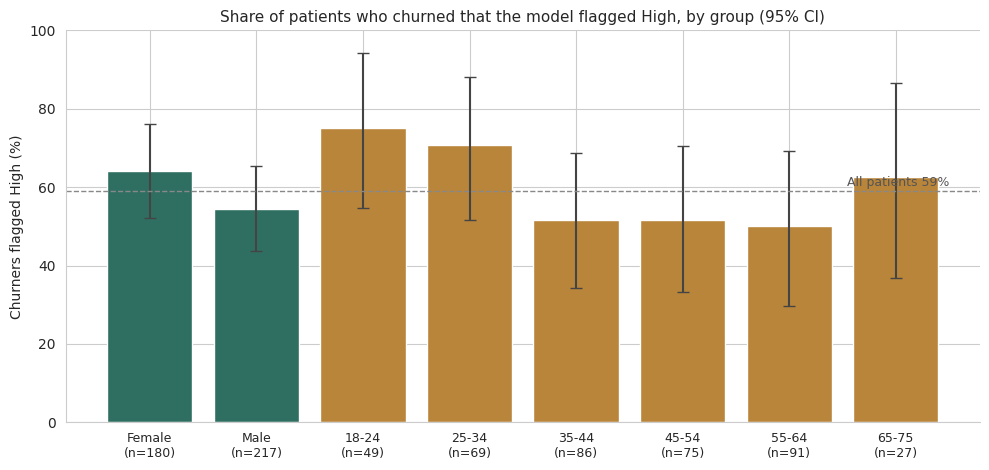

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Saved fairness_by_group.csv and fairness_equal_opportunity.png


In [32]:
# ===== Fairness check on the 397 holdout rows: paste into ONE new Colab cell =====
# Upload holdout_for_live_test.csv when asked (it is in C:\livetest).
# Because the live service matched the saved model on 397/397 rows, these
# probabilities are exactly what the deployed system produces.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from google.colab import files

print("Choose holdout_for_live_test.csv ...")
files.upload()
df = pd.read_csv("holdout_for_live_test.csv")

HIGH, MEDIUM = 0.55, 0.35          # risk tier thresholds from the model package
B = 2000                           # bootstrap resamples
SMALL = 30                         # groups below this size are flagged as unreliable
rng = np.random.default_rng(42)

df["y"] = df["actual_churned"].astype(int)
df["p"] = df["expected_probability"].astype(float)
df["high"] = (df["p"] >= HIGH).astype(int)
df["high_or_medium"] = (df["p"] >= MEDIUM).astype(int)


def point_metrics(g):
    y, p, h, hm = g["y"].values, g["p"].values, g["high"].values, g["high_or_medium"].values
    churners = y == 1
    return {
        "auc": roc_auc_score(y, p) if 0 < y.sum() < len(y) else np.nan,
        "recall_high": h[churners].mean() if churners.any() else np.nan,          # equal opportunity
        "recall_high_or_medium": hm[churners].mean() if churners.any() else np.nan,
        "flag_rate_high": h.mean(),
        "precision_high": y[h == 1].mean() if h.sum() else np.nan,
        "false_alarm_rate_high": h[~churners].mean() if (~churners).any() else np.nan,
        "mean_predicted": p.mean(),
        "actual_churn_rate": y.mean(),
    }


def bootstrap_ci(g, key):
    vals = []
    idx = np.arange(len(g))
    for _ in range(B):
        s = g.iloc[rng.choice(idx, size=len(idx), replace=True)]
        v = point_metrics(s)[key]
        if not np.isnan(v):
            vals.append(v)
    if len(vals) < B * 0.5:
        return (np.nan, np.nan)
    return tuple(np.percentile(vals, [2.5, 97.5]))


def fmt(v, lo=None, hi=None, pct=True):
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return "-"
    s = f"{v*100:.1f}%" if pct else f"{v:.3f}"
    if lo is not None and not np.isnan(lo):
        s += f" ({lo*100:.0f}-{hi*100:.0f}%)" if pct else f" ({lo:.2f}-{hi:.2f})"
    return s


rows = []
for attribute in ["Gender", "Age_Group"]:
    groups = [("All patients", df)] if attribute == "Gender" else []
    groups += [(str(k), g) for k, g in df.groupby(attribute)]
    for name, g in groups:
        m = point_metrics(g)
        auc_ci = bootstrap_ci(g, "auc")
        rec_ci = bootstrap_ci(g, "recall_high")
        rows.append({
            "Attribute": "Overall" if name == "All patients" else attribute,
            "Group": name,
            "n": len(g),
            "Churners": int(g["y"].sum()),
            "Small group": "yes" if len(g) < SMALL or g["y"].sum() < 10 else "",
            "ROC-AUC (95% CI)": fmt(m["auc"], *auc_ci, pct=False),
            "Churners flagged High (95% CI)": fmt(m["recall_high"], *rec_ci),
            "Churners flagged High or Medium": fmt(m["recall_high_or_medium"]),
            "Flagged High": fmt(m["flag_rate_high"]),
            "Precision of High flag": fmt(m["precision_high"]),
            "False alarms (stayers flagged High)": fmt(m["false_alarm_rate_high"]),
            "Mean predicted risk": fmt(m["mean_predicted"]),
            "Actual churn rate": fmt(m["actual_churn_rate"]),
            "_recall": m["recall_high"], "_lo": rec_ci[0], "_hi": rec_ci[1],
        })

table = pd.DataFrame(rows)
show = table.drop(columns=["_recall", "_lo", "_hi"])
pd.set_option("display.max_columns", None, "display.width", 250)
print("\n=========== FAIRNESS CHECK (holdout, n = %d) ===========\n" % len(df))
print(show.to_string(index=False))

# Gender gap in equal opportunity, with a bootstrap CI for the difference
genders = sorted(df["Gender"].dropna().unique())
if len(genders) == 2:
    a, b = genders
    ga, gb = df[df["Gender"] == a], df[df["Gender"] == b]
    diff = point_metrics(ga)["recall_high"] - point_metrics(gb)["recall_high"]
    diffs = []
    for _ in range(B):
        sa = ga.iloc[rng.integers(0, len(ga), len(ga))]
        sb = gb.iloc[rng.integers(0, len(gb), len(gb))]
        d = point_metrics(sa)["recall_high"] - point_metrics(sb)["recall_high"]
        if not np.isnan(d):
            diffs.append(d)
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    verdict = "no clear difference (the interval includes 0)" if lo <= 0 <= hi else "a difference unlikely to be chance (the interval excludes 0)"
    print(f"\nChurners flagged High, {a} minus {b}: {diff*100:+.1f} points (95% CI {lo*100:+.1f} to {hi*100:+.1f}) -> {verdict}")

# Figure for the report: equal opportunity by group, with 95% CIs
plot = table[table["Attribute"] != "Overall"].copy()
overall = table[table["Attribute"] == "Overall"]["_recall"].iloc[0]
labels = [f"{r.Group}\n(n={r.n})" for r in plot.itertuples()]
vals = plot["_recall"].values * 100
err = np.array([vals - plot["_lo"].values * 100, plot["_hi"].values * 100 - vals])
colors = ["#2f6f62" if a == "Gender" else "#b9853a" for a in plot["Attribute"]]

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.bar(range(len(vals)), vals, color=colors, yerr=err, capsize=4, ecolor="#444")
ax.axhline(overall * 100, color="#888", linestyle="--", linewidth=1)
ax.text(len(vals) - 0.5, overall * 100 + 1.5, f"All patients {overall*100:.0f}%", ha="right", color="#555", fontsize=9)
ax.set_xticks(range(len(vals)))
ax.set_xticklabels(labels, fontsize=9)
ax.set_ylabel("Churners flagged High (%)")
ax.set_ylim(0, 100)
ax.set_title("Share of patients who churned that the model flagged High, by group (95% CI)", fontsize=11)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.savefig("fairness_equal_opportunity.png", dpi=200)
plt.show()

show.to_csv("fairness_by_group.csv", index=False)
files.download("fairness_by_group.csv")
files.download("fairness_equal_opportunity.png")
print("\nSaved fairness_by_group.csv and fairness_equal_opportunity.png")

In [33]:
# ===== Fairness ablation: does removing Gender (and Age) close the gap, and at what cost? =====
# Paste into ONE new cell at the END of the notebook, after a full "Run all".
# Uses the notebook's own X_train, X_test, y_train, y_test, FEATURE_COLS, CATEGORICAL_COLS,
# NUMERICAL_COLS, candidate_models and RANDOM_SEED. The deployed model is NOT changed.

import numpy as np
import pandas as pd
from math import sqrt, erf
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import roc_auc_score, average_precision_score
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from google.colab import files

HIGH = 0.55          # same High threshold as the deployed model
B = 1000             # bootstrap resamples for the AUC change
rng = np.random.default_rng(RANDOM_SEED)

y = np.asarray(y_test).astype(int)
gender = X_test["Gender"].astype(str).values
female, male = gender == "Female", gender == "Male"
assert female.sum() + male.sum() == len(y), f"Unexpected Gender values: {set(gender)}"


def train_and_score(drop):
    cols = [c for c in FEATURE_COLS if c not in drop]
    num = [c for c in NUMERICAL_COLS if c in cols]
    cat = [c for c in CATEGORICAL_COLS if c in cols]
    pre = ColumnTransformer([
        ("num", StandardScaler(), num),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat),
    ])
    pipe = ImbPipeline([
        ("preprocess", pre),
        ("smote", SMOTE(random_state=RANDOM_SEED)),
        ("clf", clone(candidate_models["XGBoost"])),
    ])
    pipe.fit(X_train[cols], y_train)
    return pipe.predict_proba(X_test[cols])[:, 1], len(cols)


def two_prop_p(k1, n1, k2, n2):
    p = (k1 + k2) / (n1 + n2)
    se = sqrt(p * (1 - p) * (1 / n1 + 1 / n2))
    if se == 0:
        return float("nan")
    z = (k1 / n1 - k2 / n2) / se
    return 2 * (1 - 0.5 * (1 + erf(abs(z) / sqrt(2))))


def group_stats(p, mask):
    flag = p[mask] >= HIGH
    yy = y[mask]
    return {
        "n": int(mask.sum()),
        "flagged": int(flag.sum()),
        "churners": int(yy.sum()),
        "caught": int((flag & (yy == 1)).sum()),
        "stayers": int((yy == 0).sum()),
        "false_alarms": int((flag & (yy == 0)).sum()),
    }


variants = [
    ("Baseline (all features)", []),
    ("Without Gender", ["Gender"]),
    ("Without Gender and Age", ["Gender", "Age", "Age_Group"]),
]

probs, rows = {}, []
for name, drop in variants:
    print(f"Training: {name} ...")
    p, n_feat = train_and_score(drop)
    probs[name] = p
    f, m = group_stats(p, female), group_stats(p, male)
    rows.append({
        "Model": name,
        "Features": n_feat,
        "ROC-AUC": round(roc_auc_score(y, p), 3),
        "Average precision": round(average_precision_score(y, p), 3),
        "Flagged High (all)": f"{(p >= HIGH).mean()*100:.1f}%",
        "Flagged High: F / M": f"{f['flagged']/f['n']*100:.1f}% / {m['flagged']/m['n']*100:.1f}%",
        "Flag gap p-value": round(two_prop_p(f["flagged"], f["n"], m["flagged"], m["n"]), 3),
        "False alarms: F / M": f"{f['false_alarms']/f['stayers']*100:.1f}% / {m['false_alarms']/m['stayers']*100:.1f}%",
        "False-alarm gap p-value": round(two_prop_p(f["false_alarms"], f["stayers"], m["false_alarms"], m["stayers"]), 3),
        "Churners caught: F / M": f"{f['caught']/f['churners']*100:.1f}% / {m['caught']/m['churners']*100:.1f}%",
    })

# Paired bootstrap: change in ROC-AUC compared with the baseline, on the same resampled patients
base = probs[variants[0][0]]
idx = np.arange(len(y))
for row in rows[1:]:
    p = probs[row["Model"]]
    diffs = []
    for _ in range(B):
        s = rng.choice(idx, size=len(idx), replace=True)
        if 0 < y[s].sum() < len(s):
            diffs.append(roc_auc_score(y[s], p[s]) - roc_auc_score(y[s], base[s]))
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    d = roc_auc_score(y, p) - roc_auc_score(y, base)
    row["AUC change vs baseline (95% CI)"] = f"{d:+.3f} ({lo:+.3f} to {hi:+.3f})"
rows[0]["AUC change vs baseline (95% CI)"] = "-"

result = pd.DataFrame(rows).set_index("Model").T
pd.set_option("display.width", 200, "display.max_colwidth", 60)
print("\n============ FAIRNESS ABLATION (holdout, n = %d) ============\n" % len(y))
print(result.to_string())
print("\nCheck: the baseline ROC-AUC should be 0.778, matching the deployed model.")

result.to_csv("fairness_ablation.csv")
files.download("fairness_ablation.csv")

Training: Baseline (all features) ...
Training: Without Gender ...
Training: Without Gender and Age ...

============ FAIRNESS ABLATION (holdout, n = 397) ============

Model                           Baseline (all features)             Without Gender     Without Gender and Age
Features                                             19                         18                         16
ROC-AUC                                           0.778                       0.77                      0.752
Average precision                                 0.711                      0.735                      0.706
Flagged High (all)                                33.2%                      35.0%                      32.0%
Flagged High: F / M                       38.9% / 28.6%              32.2% / 37.3%              26.7% / 36.4%
Flag gap p-value                                   0.03                      0.288                      0.038
False alarms: F / M                       23.9% / 13.8%      

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>